In [1]:
import pandas as pd
import numpy as np
from prophet import Prophet
import matplotlib.pyplot as plt

Importing plotly failed. Interactive plots will not work.


In [2]:
# 1. Data Loading & Preprocessing

# Load dataset
df = pd.read_csv('dataset.csv')

# Convert dates to datetime objects handling mixed formats
df['date_gr'] = pd.to_datetime(df['date_gr'], format='mixed')

# Clean price column (remove commas and convert to float)
df['price_avg'] = df['price_avg'].astype(str).str.replace(',', '').astype(float)

# Sort chronologically
df = df.sort_values('date_gr').reset_index(drop=True)

In [3]:
# 2. Regime Shift: Filtering Recent Data (2018+)

# Economic structure shifted post-2018; limiting training data for better accuracy
df_recent = df[df['date_gr'] >= '2018-01-01'].copy()

# Prepare data specifically for Prophet model requirements ('ds' and 'y')
df_prophet = df_recent[['date_gr', 'price_avg']].copy()
df_prophet.columns = ['ds', 'y']

# Apply Log Transformation to handle the exponential growth nature of the data
df_prophet['y'] = np.log(df_prophet['y'])

In [ ]:
# 3. Model Training (Prophet)

# Initialize Prophet with high sensitivity to recent trend changes (changepoint_prior_scale)
m = Prophet(
    yearly_seasonality=True, 
    weekly_seasonality=False,  # Disable weekly noise to focus on macro trends
    daily_seasonality=False,
    changepoint_prior_scale=0.5 
)

# Train the model
m.fit(df_prophet)

In [5]:
# 4. Forecasting (Next 30 Days)

future_dates = m.make_future_dataframe(periods=30, freq='D')
forecast = m.predict(future_dates)

# Reverse log transformation for the future segment
forecast_future_only = forecast.iloc[-30:]
predicted_prices = np.exp(forecast_future_only['yhat'])
lower_bound = np.exp(forecast_future_only['yhat_lower'])
upper_bound = np.exp(forecast_future_only['yhat_upper'])


In [6]:
# 5. Market Anomaly (Bubble) Detection
last_actual_date = df_recent['date_gr'].iloc[-1]
last_actual_price = df_recent['price_avg'].iloc[-1]

# Extract model's intrinsic value (trend prediction) for the exact last day
forecast_last_day = forecast[forecast['ds'] == last_actual_date]
predicted_trend_price = np.exp(forecast_last_day['yhat'].values[0])

# Calculate bubble percentage
bubble_percent = ((last_actual_price - predicted_trend_price) / predicted_trend_price) * 100

print("--- Market Anomaly Detected ---")
print(f"Date: {last_actual_date.date()}")
print(f"Actual Price: {last_actual_price:,.0f} IRR")
print(f"Model Intrinsic Trend: {predicted_trend_price:,.0f} IRR")
print(f"Bubble: +{bubble_percent:.1f}%")


--- Market Anomaly Detected ---
Date: 2026-10-07
Actual Price: 2,667,000 IRR
Model Intrinsic Trend: 2,252,278 IRR
Bubble: +18.4%


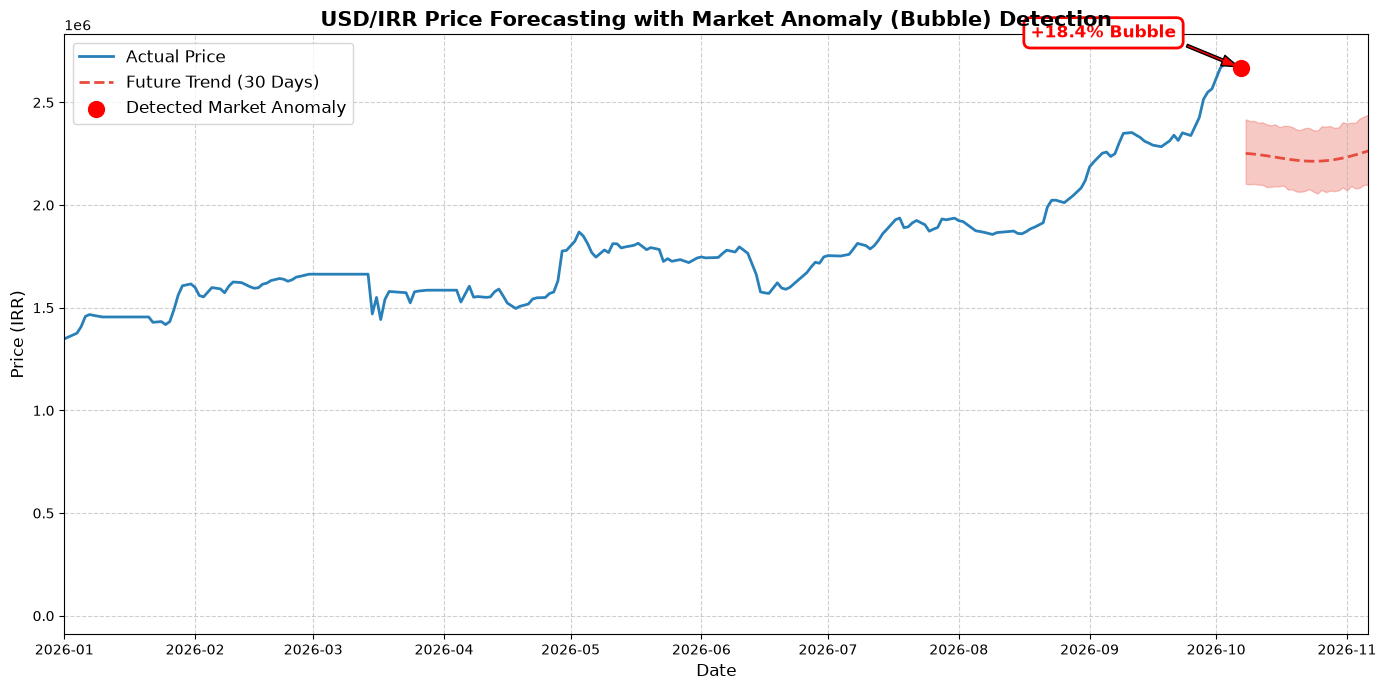

In [7]:
# 6. Visualization

plt.figure(figsize=(14, 7))

# Plot actual historical prices
plt.plot(df_recent['date_gr'], df_recent['price_avg'], label='Actual Price', color='#2980b9', linewidth=2)

# Plot forecast and confidence interval
plt.plot(forecast_future_only['ds'], predicted_prices, label='Future Trend (30 Days)', color='#e74c3c', linewidth=2, linestyle='--')
plt.fill_between(forecast_future_only['ds'], lower_bound, upper_bound, color='#e74c3c', alpha=0.3)

# Highlight market anomaly (bubble)
plt.scatter(last_actual_date, last_actual_price, color='red', s=130, zorder=5, label='Detected Market Anomaly')
plt.annotate(
    f'+{bubble_percent:.1f}% Bubble',
    xy=(last_actual_date, last_actual_price),
    xytext=(last_actual_date - pd.Timedelta(days=50), last_actual_price + 150000), 
    arrowprops=dict(facecolor='red', shrink=0.05, width=2, headwidth=8),
    fontsize=12, color='red', fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="red", lw=2)
)

# Formatting
plt.title('USD/IRR Price Forecasting with Market Anomaly (Bubble) Detection', fontsize=15, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (IRR)', fontsize=12)
plt.xlim(pd.to_datetime('2026-01-01'), forecast_future_only['ds'].max())
plt.legend(loc='upper left', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()